# 9. Stars and noise

The noise side of the parametric model: a PHOENIX stellar SED from
(T_eff, log g, [Fe/H]), normalised to a magnitude, run through slicersim to
get the per-channel depth uncertainty. This notebook shows the SED grid, the
Vega→AB conversion, how the error bar scales with brightness and band, the
bright-host saturation floor, and the CBE vs EOL instrument configurations.
`lazuli_exo.slicer.depth_error` imports slicersim lazily, so it must be
installed to run this notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
try:
    plt.style.use("gks")
except OSError:
    pass

from lazuli_exo import star, slicer, tables

g = tables.load_phoenix_grid()
print("PHOENIX grid:", g["log_flam"].shape, "| T_eff", g["teff_K"].min(), "-", g["teff_K"].max(), "K",
      "| log g", list(g["logg"]), "| [Fe/H]", list(g["feh"]))
print("native resolution per folder:", g["meta"]["native_R"])

PHOENIX grid: (56, 4, 5, 2121) | T_eff 2000.0 - 8000.0 K | log g [np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)] | [Fe/H] [np.float64(-1.0), np.float64(-0.5), np.float64(0.0), np.float64(0.3), np.float64(0.5)]
native resolution per folder: {'phoenixm10': 741, 'phoenixm05': 741, 'phoenixm00': 13657, 'phoenixp03': 741, 'phoenixp05': 741}


## Stellar SEDs

Trilinear interpolation in (log T_eff, log g, [Fe/H]). Below 2000 K the function falls back to a blackbody and says so; log g and [Fe/H] clamp to the grid edges and say so.

(1800, 5.0, 0.0) -> {'fallback': 'blackbody', 'clamped': {}, 'teff_K': 1800.0, 'logg_used': 5.0, 'feh_used': 0.0, 'grid': 'blackbody'}
(3000, 5.3, 0.6) -> {'fallback': None, 'clamped': {'logg': (5.3, 5.0), 'feh': (0.6, 0.5)}, 'teff_K': 3000.0, 'logg_used': 5.0, 'feh_used': 0.5, 'grid': 'phoenix'}


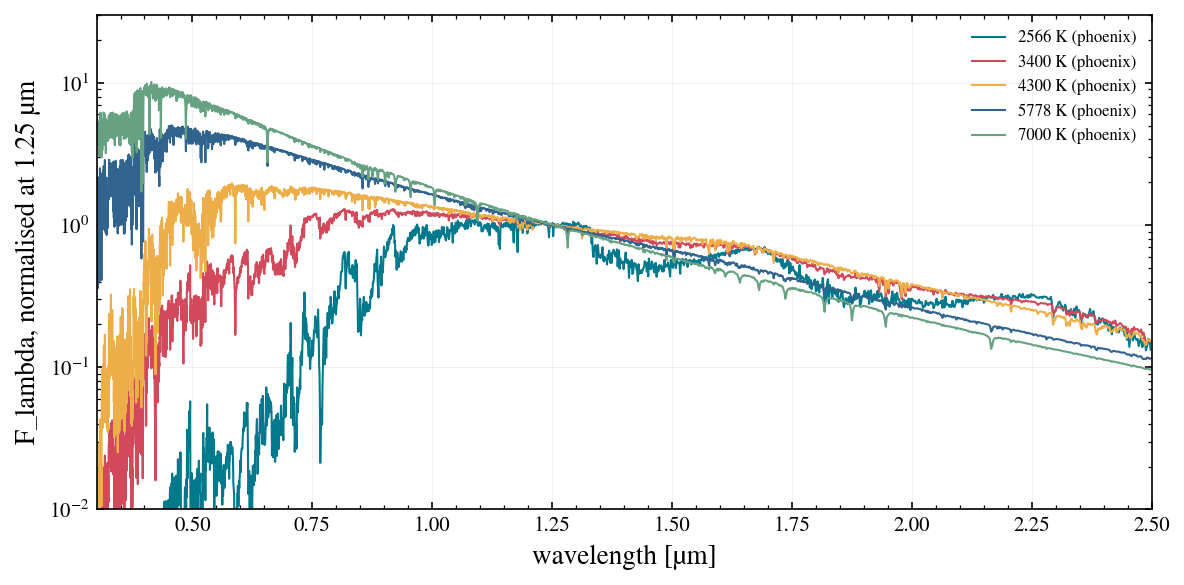

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
for teff in (2566, 3400, 4300, 5778, 7000):
    wl_A, f, info = star.phoenix_sed(teff, 4.5, 0.0)
    ax.plot(wl_A / 1e4, f / f[(wl_A > 12000) & (wl_A < 13000)].mean(), lw=1, label=f"{teff} K ({info['grid']})")
ax.set_xlim(0.3, 2.5); ax.set_yscale("log"); ax.set_ylim(1e-2, 30)
ax.set_xlabel("wavelength [µm]"); ax.set_ylabel("F_lambda, normalised at 1.25 µm"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
for teff, logg, feh in ((1800, 5.0, 0.0), (3000, 5.3, 0.6)):
    print((teff, logg, feh), "->", star.phoenix_sed(teff, logg, feh)[2])

## Vega → AB

slicersim normalises magnitudes in the AB system. Archive magnitudes (2MASS J/H/Ks, Johnson V) are Vega. The offsets come from sncosmo's band definitions and are independent of the spectrum; `depth_error` applies them for `mag_system="vega"` and reports the offset in `info`.

In [3]:
for band in ("V", "J", "H", "Ks"):
    print(f"{band:2s}: m_AB - m_Vega = {slicer.vega_to_ab_offset(band):+.3f}")

V : m_AB - m_Vega = +0.010
J : m_AB - m_Vega = +0.899
H : m_AB - m_Vega = +1.373
Ks: m_AB - m_Vega = +1.843


## Error bar vs brightness

For a Sun-like star and a 3 h transit: the median single-transit depth error against J magnitude. Faint stars are photon-limited (σ ∝ 10^(0.2 J)); bright stars hit slicersim's shortest readout (2 groups × 1 frame) and residual saturation is reported rather than hidden.

J =  5.0  median sigma =      41 ppm  nmd = [2, 1, 0]  saturated px = 4808


J =  6.0  median sigma =      41 ppm  nmd = [2, 1, 0]  saturated px = 1788


J =  7.0  median sigma =      47 ppm  nmd = [2, 1, 0]  saturated px = 236


J =  8.0  median sigma =      64 ppm  nmd = [2, 2, 0]  saturated px = 0


J =  9.0  median sigma =      97 ppm  nmd = [2, 4, 0]  saturated px = 0


J = 10.0  median sigma =     151 ppm  nmd = [2, 8, 0]  saturated px = 0


J = 11.0  median sigma =     228 ppm  nmd = [4, 8, 0]  saturated px = 0


J = 12.0  median sigma =     357 ppm  nmd = [8, 8, 0]  saturated px = 0
J = 13.0  median sigma =     564 ppm  nmd = [16, 8, 0]  saturated px = 0


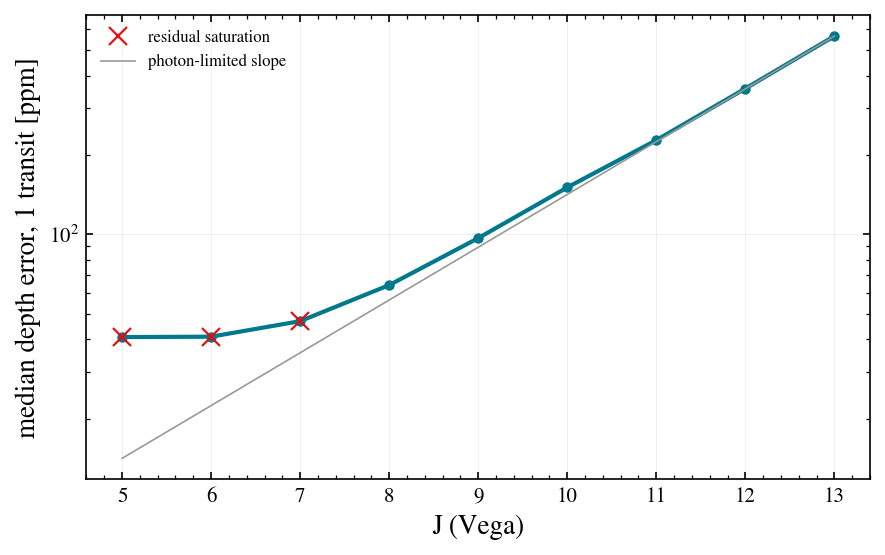

In [4]:
wl_A, flam, _ = star.phoenix_sed(5778, 4.44, 0.0)
mags = np.arange(5.0, 13.1, 1.0)
rows = []
for J in mags:
    wl, err, info = slicer.depth_error(wl_A, flam, mag=J, band="J", mag_system="vega", t14_s=3 * 3600)
    rows.append((J, np.median(err) * 1e6, info["nmd_used"], info["nsaturated_detpx"], info["t_obs_s"]))
    print(f"J = {J:4.1f}  median sigma = {rows[-1][1]:7.0f} ppm  nmd = {info['nmd_used']}  saturated px = {info['nsaturated_detpx']}")
fig, ax = plt.subplots(figsize=(6, 3.8))
r = np.array([(x[0], x[1], x[3]) for x in rows])
ax.plot(r[:, 0], r[:, 1], "o-", ms=4)
ax.plot(r[r[:, 2] > 0, 0], r[r[:, 2] > 0, 1], "rx", ms=9, label="residual saturation")
ax.plot(mags, rows[-1][1] * 10 ** (0.2 * (mags - mags[-1])), "0.6", lw=0.8, label="photon-limited slope")
ax.set_yscale("log"); ax.set_xlabel("J (Vega)"); ax.set_ylabel("median depth error, 1 transit [ppm]"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

## Which band to quote the magnitude in

The same star given in J, H, Ks or V. A consistent SED gives nearly the same answer whichever band is used, since slicersim renormalises the whole spectrum; small differences come from the band offsets and the SED shape.

In [5]:
# a 5778 K star with J = 10 has roughly V = 11.1, H = 9.7, Ks = 9.65 (Vega); use the SED itself to be consistent
import sncosmo
spec = sncosmo.Spectrum(wl_A, flam)
J = 10.0
for band in ("V", "J", "H", "Ks"):
    m = J + (spec.bandmag(slicer.BANDS[band], "vega") - spec.bandmag(slicer.BANDS["J"], "vega"))
    _, err, info = slicer.depth_error(wl_A, flam, mag=m, band=band, mag_system="vega", t14_s=3 * 3600)
    print(f"given {band:2s} = {m:6.2f} Vega -> {info['mag_ab']:6.2f} AB: median sigma {np.median(err)*1e6:5.0f} ppm")

given V  =  11.16 Vega ->  11.17 AB: median sigma   151 ppm


given J  =  10.00 Vega ->  10.90 AB: median sigma   151 ppm


given H  =   9.66 Vega ->  11.04 AB: median sigma   151 ppm


given Ks =   9.62 Vega ->  11.47 AB: median sigma   151 ppm


## CBE vs EOL

slicersim ships a current-best-estimate (`lazuli_cbe`) and an end-of-life (`lazuli_eol`) Lazuli configuration. `depth_error` turns any configuration problem into a `ValueError` naming the instrument, so a web page can show it instead of failing; the cell below either plots the EOL/CBE error ratio or prints why EOL is unavailable in the installed slicersim.

In [6]:
wl_c, err_c, _ = slicer.depth_error(wl_A, flam, mag=10.0, band="J", t14_s=3 * 3600, instrument="lazuli_cbe")
try:
    wl_e, err_e, _ = slicer.depth_error(wl_A, flam, mag=10.0, band="J", t14_s=3 * 3600, instrument="lazuli_eol")
except ValueError as e:
    print("EOL unavailable:", e)
else:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(wl_c, err_c * 1e6, lw=0.8, label="CBE"); ax[0].plot(wl_e, err_e * 1e6, lw=0.8, label="EOL")
    ax[0].set_yscale("log"); ax[0].set_xlabel("wavelength [µm]"); ax[0].set_ylabel("depth error per channel [ppm]"); ax[0].legend(frameon=False)
    common = np.interp(wl_c, wl_e, err_e)
    ax[1].plot(wl_c, common / err_c, lw=0.8); ax[1].set_xlabel("wavelength [µm]"); ax[1].set_ylabel("EOL / CBE error")
    fig.tight_layout()
    print(f"median EOL/CBE error ratio: {np.median(common / err_c):.2f}")

EOL unavailable: slicersim could not build instrument 'lazuli_eol': KeyError: 'telescope'


## Summary

- The PHOENIX mini-grid covers 2000–8000 K; outside it the code falls back or clamps and tells you.
- Vega→AB is +0.90 mag in J; passing an archive J without it would make every error bar ~1.4× too optimistic.
- Bright hosts (J ≲ 7) reach the readout floor and carry a residual-saturation flag; treat those error bars as indicative.